In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)
os.chdir(r'C:\Users\balca\OneDrive\Desktop\Personal\Cursos\ml-course\data')
titanic = pd.read_csv('titanic.csv', header='infer')
print(titanic.shape)
titanic.head(10)

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


# Inicializador de Información del titanic
## 1) La primera decisión se centralizó sobre el uso de la librería os para facilitar la extracción de la info en el csv
## Explicacion de las Cosas:

In [3]:
## Primeras filas
#Aqui usamos head para imprimir las primeras 5
primeras_filas = titanic.head(5)
primeras_filas

## Ultimas filas
## Aqui usamos tail para imprimir las ultimas 5
ultimas_filas = titanic.tail(5)


## Resumen ESTADISTICO de la info
titanic.info()
titanic.describe()
titanic.shape
duiplicados_numero = titanic.duplicated().sum()
duplicados_porcentaje= titanic.duplicated().mean() * 100



<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


## Al realizar la exploración, notamos lo siguiente:

## Conociendo por titanic.shape que tiene 891 filas, en base a titanic.info() vemos que datos no-nulos tienen,
## siendo la resta de not-null - 891 datos, la cantidad de nulos por columna.

 ## Columnas con mayor cantidad de datos Nulos:

### 1) Deck (Encabezando la columna con mayor data nula)
### 2) Age (Como la segunda columna con mas datos nulos) 
### 3) embark_town tiene pocos datos nulos.

# Primer contacto 20 min
## Mira antes de tocar. El objetivo es conocer el dataset, no arreglarlo.
### □ Primeras/últimas filas, shape y tipos de dato. [COMPLETADO]
### □ Resumen estadístico de numéricas y de categóricas. [COMPLETADO]
### □ Faltantes por columna (número y %), filas duplicadas y valores únicos de cada categórica 
### [107 duplicados en los datos, (12.008978675645341 %), unicos (784)]


### ¿Clasificación o regresión? · ¿Qué numérica se comporta como categórica, y qué categórica tiene orden? · ¿Qué
### parejas de columnas dicen lo mismo? Compruébalo. · ¿Qué pasa si le das alive al modelo?

### - De Clasificación.
### -- Lo demás ya lo explicamos verbalmente en tema de que categorías borraríamos y



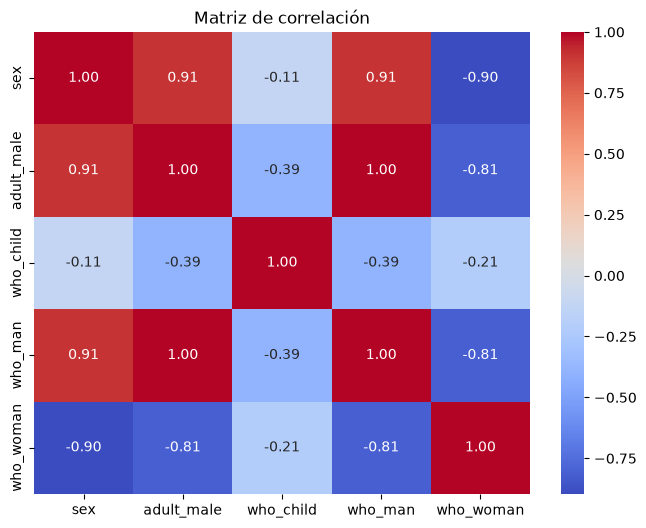

In [4]:
valores = titanic[["sex", "who", "adult_male"]].copy()
valores["sex"] = valores["sex"].map({"male":"1", "female": '0'})
valores["adult_male"] = valores["adult_male"].map({True:"1", False: "0"})
valores = pd.get_dummies(

    valores,

    columns=["who"],

    dtype=int

)

corr = valores.corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Matriz de correlación")
plt.show()

In [5]:

# survived [Completito]
# pclass [Completo: 1) First, 2) Second, 3) Third]

#titanic["sex"] = titanic["sex"].map({"male":0,"female":1})
## Quitar class, adult_male
titanic["age"].max()


np.float64(80.0)